<a href="https://colab.research.google.com/github/DebapriyaGhosh/debapriya_portfolio/blob/main/Industrial_Machine_Failure.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn joblib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.model_selection import GridSearchCV

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import requests
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"

response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    csv_file = [f for f in z.namelist() if f.endswith(".csv")][0]

    with z.open(csv_file) as file:
        df = pd.read_csv(file)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
# Display first five records
print("First Five Records:")
display(df.head())

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

First Five Records:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000



Column Names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


In [5]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Target distribution
print("\nMachine Failure Distribution:")
print(df["Machine failure"].value_counts())

Missing Values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicate Records:
0

Machine Failure Distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


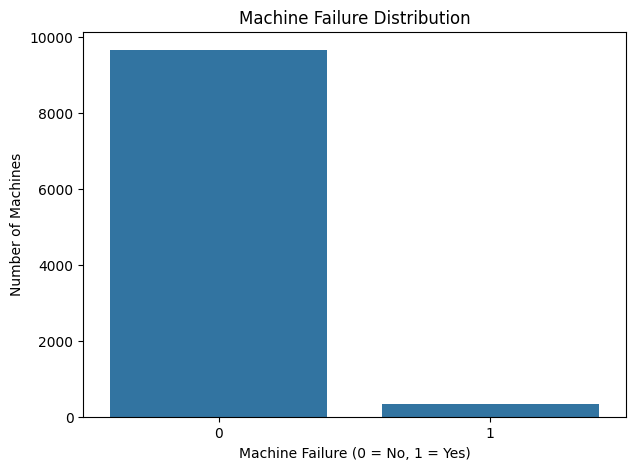

In [6]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x="Machine failure")

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Machines")

plt.show()

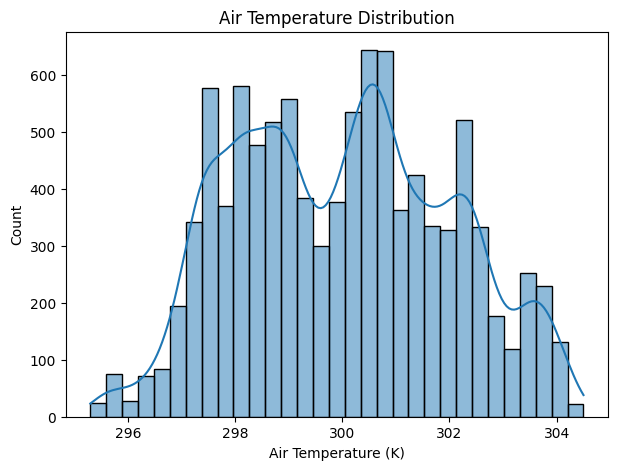

In [7]:
plt.figure(figsize=(7,5))

sns.histplot(df["Air temperature [K]"], kde=True)

plt.title("Air Temperature Distribution")
plt.xlabel("Air Temperature (K)")

plt.show()

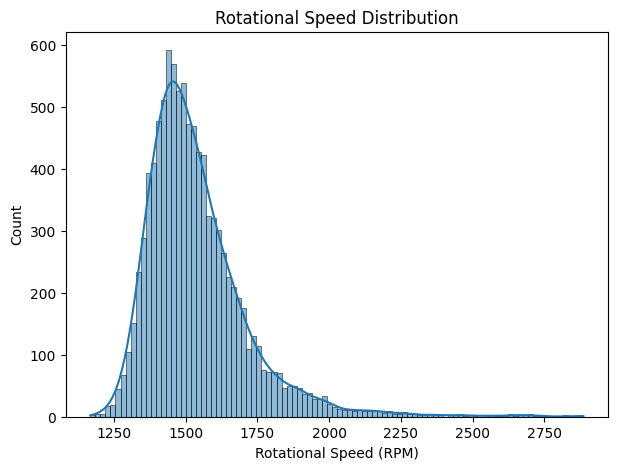

In [8]:
plt.figure(figsize=(7,5))

sns.histplot(df["Rotational speed [rpm]"], kde=True)

plt.title("Rotational Speed Distribution")
plt.xlabel("Rotational Speed (RPM)")

plt.show()

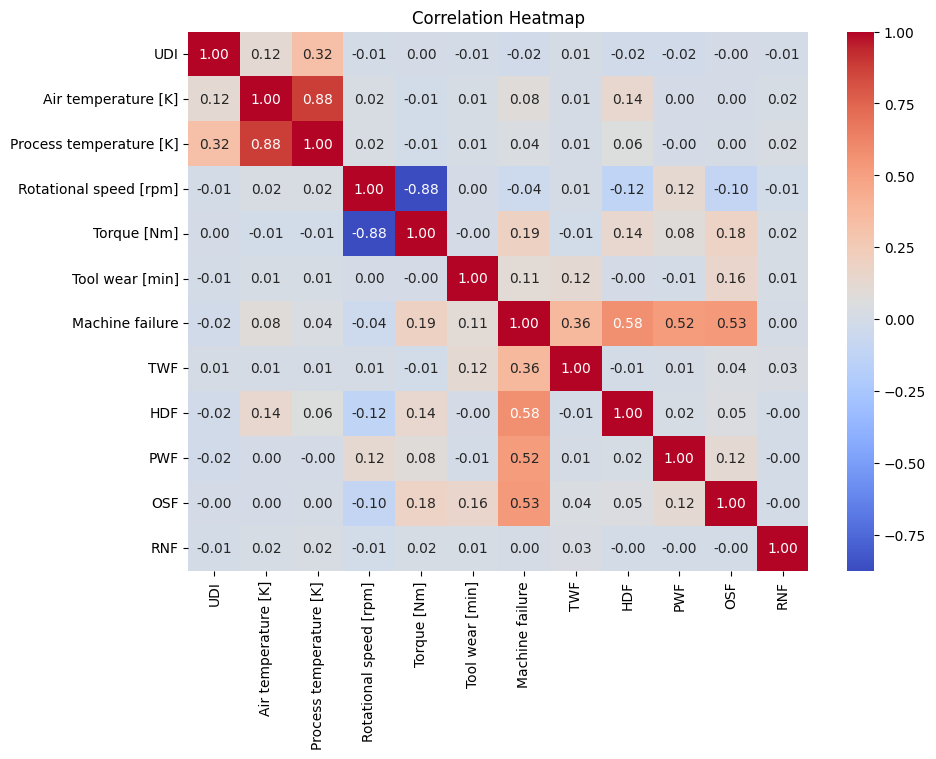

In [9]:
plt.figure(figsize=(10,7))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [10]:
# Remove duplicate records
df = df.drop_duplicates()

# Define input features
X = df[
    [
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
]

# Define target variable
y = df["Machine failure"]

print("Input Features:")
display(X.head())

print("\nTarget Variable:")
display(y.head())

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features:


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9



Target Variable:


,Machine failure
0,0
1,0
2,0
3,0
4,0



Feature Shape: (10000, 6)
Target Shape: (10000,)


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data: (8000, 6)
Testing Data: (2000, 6)

Training Target Distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing Target Distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [12]:
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

categorical_features = ["Type"]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [13]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    )
}

pipelines = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    pipelines[name] = pipeline

    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [14]:
results = []

for name, model in pipelines.items():

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

comparison = pd.DataFrame(results)

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8245,0.1418,0.8235,0.2419
1,Decision Tree,0.9775,0.6949,0.6029,0.6457
2,Random Forest,0.9800,0.9667,0.4265,0.5918


In [15]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in pipelines.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Fold 1": scores[0],
        "Fold 2": scores[1],
        "Fold 3": scores[2],
        "Fold 4": scores[3],
        "Fold 5": scores[4],
        "Average F1": scores.mean()
    })

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(4))

,Model,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Average F1
0,Logistic Regression,0.2474,0.2196,0.2310,0.2439,0.2310,0.2346
1,Decision Tree,0.6538,0.5393,0.6392,0.6296,0.6170,0.6158
2,Random Forest,0.5974,0.5067,0.5455,0.5250,0.4737,0.5296


In [16]:
param_grids = {

    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10],
        "classifier__solver": ["liblinear"]
    },

    "Decision Tree": {
        "classifier__max_depth": [None, 5, 10, 20],
        "classifier__min_samples_split": [2, 5, 10],
        "classifier__min_samples_leaf": [1, 2, 4]
    },

    "Random Forest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [None, 10, 20],
        "classifier__min_samples_split": [2, 5],
        "classifier__min_samples_leaf": [1, 2]
    }
}

best_models = {}
tuning_results = []

for name, model in pipelines.items():

    print("Tuning:", name)

    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        verbose=0
    )

    grid.fit(X_train, y_train)

    best_models[name] = grid.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV F1": grid.best_score_,
        "Best Parameters": grid.best_params_
    })

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df)

Tuning: Logistic Regression
Tuning: Decision Tree
Tuning: Random Forest


,Model,Best CV F1,Best Parameters
0,Logistic Regression,0.234322,"{'classifier__C': 1, 'classifier__solver': 'li..."
1,Decision Tree,0.642014,"{'classifier__max_depth': None, 'classifier__m..."
2,Random Forest,0.642547,"{'classifier__max_depth': None, 'classifier__m..."


In [17]:
best_model_name = tuning_df.loc[
    tuning_df["Best CV F1"].idxmax(),
    "Model"
]

best_model = best_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Random Forest


In [18]:
y_pred = best_model.predict(X_test)

print("Selected Model:", best_model_name)

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No Failure", "Failure"],
    zero_division=0
))

Selected Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1932
     Failure       0.80      0.60      0.69        68

    accuracy                           0.98      2000
   macro avg       0.90      0.80      0.84      2000
weighted avg       0.98      0.98      0.98      2000



In [19]:
def predict_machine_failure():

    print("MACHINE FAILURE PREDICTION SYSTEM")

    machine_type = input(
        "Enter Machine Type (L, M, H): "
    ).upper()

    air_temp = float(input(
        "Enter Air Temperature (K): "
    ))

    process_temp = float(input(
        "Enter Process Temperature (K): "
    ))

    rpm = float(input(
        "Enter Rotational Speed (RPM): "
    ))

    torque = float(input(
        "Enter Torque (Nm): "
    ))

    tool_wear = float(input(
        "Enter Tool Wear (minutes): "
    ))

    new_data = pd.DataFrame([{
        "Type": machine_type,
        "Air temperature [K]": air_temp,
        "Process temperature [K]": process_temp,
        "Rotational speed [rpm]": rpm,
        "Torque [Nm]": torque,
        "Tool wear [min]": tool_wear
    }])

    prediction = best_model.predict(new_data)[0]

    probability = best_model.predict_proba(
        new_data
    )[0][1]

    print("\n========== PREDICTION RESULT ==========")

    if prediction == 1:

        print("Machine Failure: YES")

    else:

        print("Machine Failure: NO")

    print(
        "Failure Probability:",
        round(probability * 100, 2),
        "%"
    )

    print("======================================")

predict_machine_failure()

MACHINE FAILURE PREDICTION SYSTEM
Enter Machine Type (L, M, H): M
Enter Air Temperature (K): 300
Enter Process Temperature (K): 100
Enter Rotational Speed (RPM): 1000
Enter Torque (Nm): 30
Enter Tool Wear (minutes): 100

========== PREDICTION RESULT ==========
Machine Failure: NO
Failure Probability: 1.93 %


In [20]:
model_data = {
    "model": best_model,
    "model_name": best_model_name,
    "features": X.columns.tolist()
}

joblib.dump(
    model_data,
    "best_machine_failure_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [21]:
import joblib

saved_model = joblib.load(
    "best_machine_failure_model.pkl"
)

loaded_model = saved_model["model"]

print("Model loaded successfully!")
print("Model Name:", saved_model["model_name"])

Model loaded successfully!
Model Name: Random Forest
